# EDA

The daily series from `data/daily.parquet`. Days that lost 2 hours or more to feed gaps are left out of the weekday, month, outlier and holiday numbers, since their totals are too low.

In [1]:
import holidays
import matplotlib.pyplot as plt
import pandas as pd

FIGURES = "../reports/figures/"

In [2]:
daily = pd.read_parquet("../data/daily.parquet")
daily["usable"] = daily["gap_hours"] < 2
daily["usable"].value_counts()

usable
True     1062
False      33
Name: count, dtype: int64

## Daily series

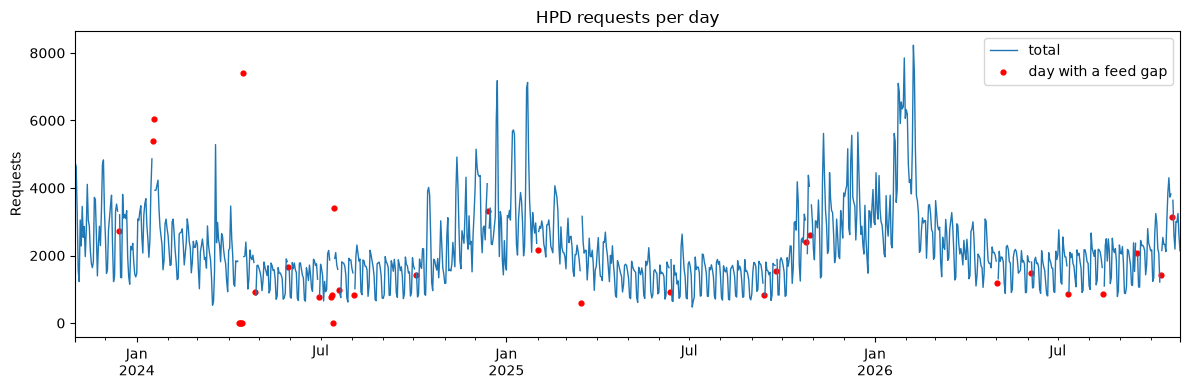

In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
daily["total"].where(daily["usable"]).plot(ax=ax, linewidth=1)
gaps = daily[~daily["usable"]]
ax.scatter(gaps.index, gaps["total"].fillna(0), color="red", s=12, label="day with a feed gap")
ax.set_title("HPD requests per day")
ax.set_xlabel("")
ax.set_ylabel("Requests")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES + "daily_requests.png", dpi=150)
plt.show()

Each winter is higher than the one before, and the summers sit at about 1,300 to 1,800 requests a day. The red points are the 33 days with feed gaps, shown at their (too low) totals or at 0 for the five missing days.

## Weekday

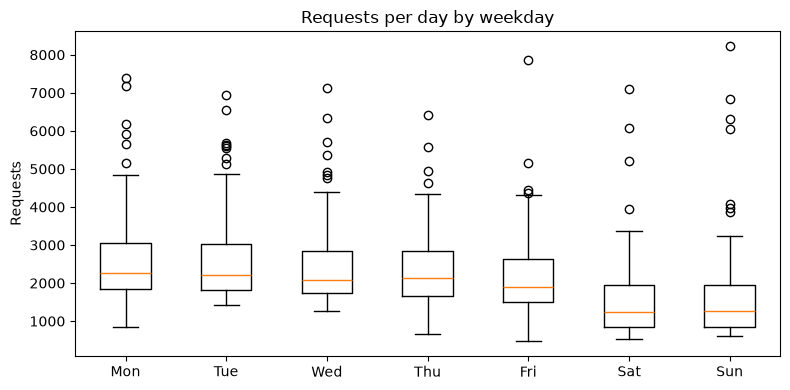

In [4]:
ok = daily[daily["usable"]].copy()
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot([ok.loc[ok["weekday"] == i, "total"] for i in range(7)], tick_labels=days)
ax.set_title("Requests per day by weekday")
ax.set_ylabel("Requests")
fig.tight_layout()
fig.savefig(FIGURES + "weekday_boxplot.png", dpi=150)
plt.show()

In [5]:
ok.groupby("weekday")["total"].agg(["mean", "median"]).round().set_axis(days)

,mean,median
Mon,2595.0,2257.0
Tue,2574.0,2214.0
Wed,2433.0,2085.0
Thu,2359.0,2130.0
Fri,2202.0,1888.0
Sat,1548.0,1231.0
Sun,1581.0,1276.0


Volume falls through the week, from a median of 2,257 on Monday to 1,888 on Friday, and weekend medians are about 40% below weekday ones. The long upper whiskers on every day are the winter peaks.

## Month

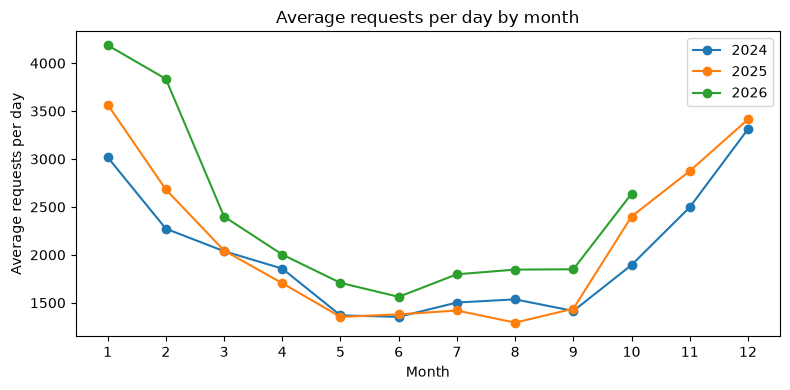

In [6]:
monthly = ok.groupby([ok.index.year, ok.index.month])["total"].mean().unstack(0)

fig, ax = plt.subplots(figsize=(8, 4))
for year in [2024, 2025, 2026]:
    ax.plot(monthly.index, monthly[year], marker="o", label=year)
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month")
ax.set_ylabel("Average requests per day")
ax.set_title("Average requests per day by month")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES + "monthly_pattern.png", dpi=150)
plt.show()

In [7]:
monthly.round()

date,2023,2024,2025,2026
date,,,,
1,NaN,3019.0,3569.0,4188.0
2,NaN,2273.0,2682.0,3836.0
3,NaN,2038.0,2045.0,2400.0
4,NaN,1856.0,1704.0,2003.0
5,NaN,1369.0,1353.0,1708.0
6,NaN,1353.0,1379.0,1562.0
7,NaN,1502.0,1420.0,1797.0
8,NaN,1536.0,1293.0,1846.0
9,NaN,1415.0,1438.0,1850.0


January is the peak and May to September the low, which follows the heating season (HEAT/HOT WATER is 38% of all requests). The winter peak grows every year, from 3,019 a day in Jan 2024 to 4,188 in Jan 2026, and summer 2026 is also higher than the two before.

## Outliers

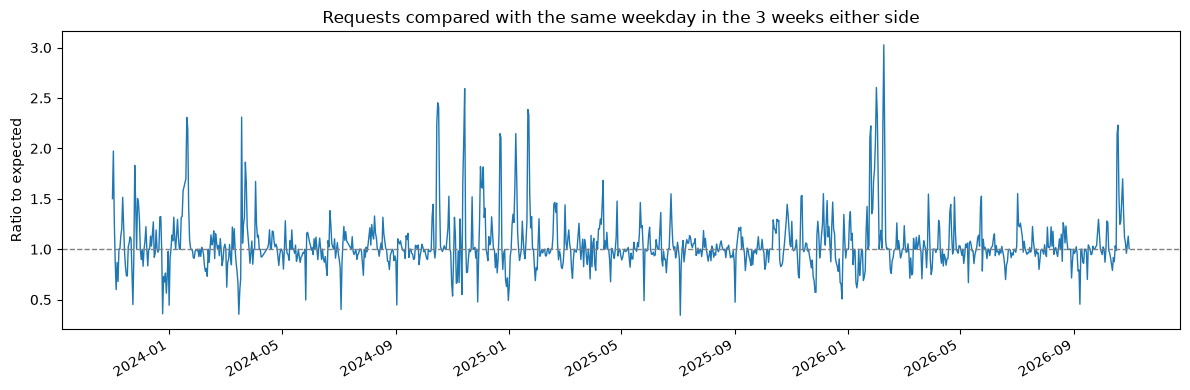

In [8]:
ok["expected"] = ok.groupby("weekday")["total"].transform(lambda x: x.rolling(7, center=True, min_periods=3).median())
ok["ratio"] = ok["total"] / ok["expected"]

fig, ax = plt.subplots(figsize=(12, 4))
ok["ratio"].plot(ax=ax, linewidth=1)
ax.axhline(1, color="grey", linestyle="--", linewidth=1)
ax.set_title("Requests compared with the same weekday in the 3 weeks either side")
ax.set_xlabel("")
ax.set_ylabel("Ratio to expected")
fig.tight_layout()
fig.savefig(FIGURES + "outlier_ratio.png", dpi=150)
plt.show()

In [9]:
raw = pd.read_parquet("../data/HPD_requests.parquet", columns=["created_date", "complaint_type"])
is_heat = raw["complaint_type"] == "HEAT/HOT WATER"
ok["heat_share"] = is_heat.groupby(raw["created_date"].dt.normalize()).mean()

ok.sort_values("ratio", ascending=False)[["total", "expected", "ratio", "heat_share"]].head(10).round(2)

,total,expected,ratio,heat_share
date,,,,
2026-02-08,8228.0,2718.0,3.03,0.74
2026-01-31,6064.0,2328.0,2.60,0.73
2024-11-14,4075.0,1571.0,2.59,0.60
2024-10-16,4017.0,1638.0,2.45,0.58
2024-10-17,3788.0,1571.0,2.41,0.53
2025-01-21,6944.0,2910.0,2.39,0.69
2025-01-22,7127.0,3053.0,2.33,0.69
2026-02-01,6316.0,2718.0,2.32,0.74
2024-03-19,5285.0,2287.0,2.31,0.43


In [10]:
ok.sort_values("ratio")[["total", "expected", "ratio", "heat_share"]].head(10).round(2)

,total,expected,ratio,heat_share
date,,,,
2025-07-04,473.0,1370.0,0.35,0.13
2024-03-16,528.0,1487.0,0.36,0.44
2023-12-25,1151.0,3201.0,0.36,0.62
2024-07-04,654.0,1623.0,0.40,0.10
2024-01-01,1472.0,3314.0,0.44,0.58
2024-09-02,835.0,1868.0,0.45,0.10
2023-11-23,1397.0,3095.0,0.45,0.64
2026-09-07,1079.0,2376.0,0.45,0.11
2025-09-01,858.0,1807.0,0.47,0.15


In [11]:
jan = ok[ok.index.month == 1]
jan["heat_share"].median()

np.float64(0.5774456521739131)

In [12]:
hours = daily.loc["2024-03-09":"2024-03-19"].index
interval = pd.read_parquet("../data/interval.parquet")
interval["total"].groupby(interval.index.normalize()).max().loc[hours]

interval
2024-03-09     82.0
2024-03-10     64.0
2024-03-11    129.0
2024-03-12    107.0
2024-03-13    122.0
2024-03-14     98.0
2024-03-15    116.0
2024-03-16     29.0
2024-03-17     29.0
2024-03-18    113.0
2024-03-19    371.0
Name: total, dtype: float64

The high days are cold snaps. On the biggest ones (20 and 21 Jan 2024, 21 and 22 Jan 2025, late Jan and early Feb 2026) HEAT/HOT WATER is 69 to 82% of requests, against a median of 58% for January. The days in mid-October 2024 look like the first cold days of the heating season. The low days are mostly holidays.

16 and 17 Mar 2024 don't fit either. They're a normal weekend in March but run at about a third of the usual volume all day, and Tuesday 19 Mar has 5,285 requests, with up to 371 in a single half-hour. That looks like a slow feed and a backlog, so these three days are treated like the gap days below.

In [13]:
daily.loc[["2024-03-16", "2024-03-17", "2024-03-19"], "usable"] = False
daily["usable"].value_counts()

usable
True     1059
False      36
Name: count, dtype: int64

## Holidays

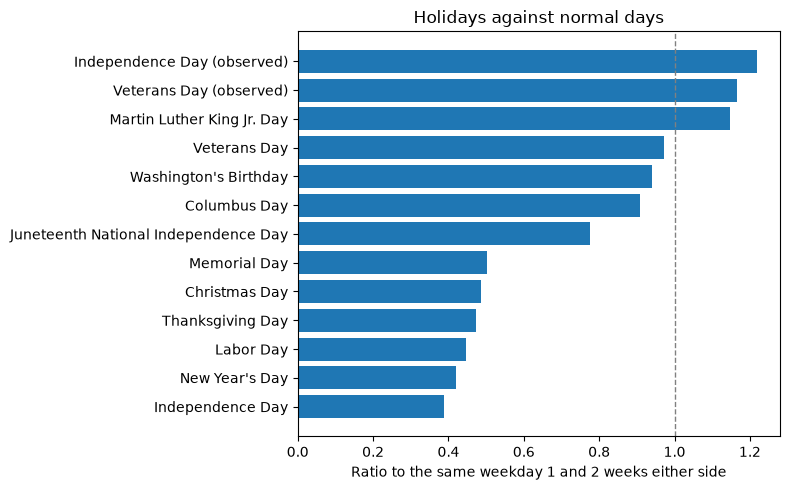

In [14]:
us_holidays = holidays.US(years=range(2023, 2027))
normal = daily["total"].where(daily["usable"] & ~daily["holiday"])

rows = []
for day in daily.index[daily["holiday"] & daily["usable"]]:
    nearby = normal.reindex([day + pd.Timedelta(weeks=k) for k in (-2, -1, 1, 2)]).mean()
    rows.append({"date": day, "holiday": us_holidays.get(day), "total": daily.loc[day, "total"], "ratio": daily.loc[day, "total"] / nearby})
hol = pd.DataFrame(rows)
by_name = hol.groupby("holiday")["ratio"].median().sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(by_name.index, by_name)
ax.axvline(1, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Ratio to the same weekday 1 and 2 weeks either side")
ax.set_title("Holidays against normal days")
fig.tight_layout()
fig.savefig(FIGURES + "holidays.png", dpi=150)
plt.show()

In [15]:
by_name.round(2)

holiday
Independence Day                        0.39
New Year's Day                          0.42
Labor Day                               0.45
Thanksgiving Day                        0.47
Christmas Day                           0.49
Memorial Day                            0.50
Juneteenth National Independence Day    0.77
Columbus Day                            0.91
Washington's Birthday                   0.94
Veterans Day                            0.97
Martin Luther King Jr. Day              1.15
Veterans Day (observed)                 1.17
Independence Day (observed)             1.22
Name: ratio, dtype: float64

There are two kinds of holiday. Independence Day, New Year's Day, Labor Day, Thanksgiving, Christmas and Memorial Day run at 39 to 50% of a normal day. Juneteenth is at 77%, and the rest (Columbus Day, Washington's Birthday, Veterans Day, MLK Day) are close to normal or a bit above. One holiday flag would mix the two, so the models should get a flag for the six big ones.

## Channels

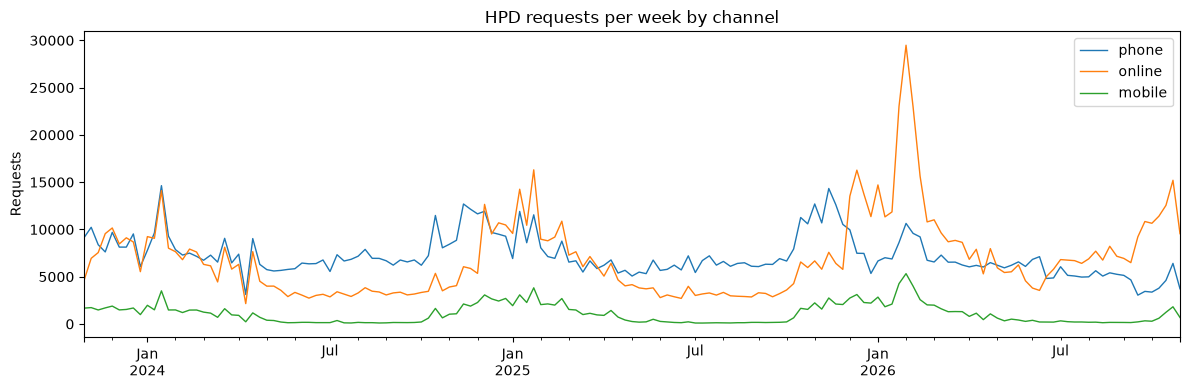

In [16]:
weekly = daily[["phone", "online", "mobile"]].resample("W").sum()

fig, ax = plt.subplots(figsize=(12, 4))
weekly.plot(ax=ax, linewidth=1)
ax.set_title("HPD requests per week by channel")
ax.set_xlabel("")
ax.set_ylabel("Requests")
fig.tight_layout()
fig.savefig(FIGURES + "weekly_by_channel.png", dpi=150)
plt.show()

In [17]:
m = daily[["phone", "online", "total"]].resample("MS").sum()
m.loc["2024-11":"2025-01"], m.loc["2025-11":"2026-01"]

(              phone   online     total
 date                                  
 2024-11-01  45918.0  21681.0   74911.0
 2024-12-01  44506.0  46432.0  102690.0
 2025-01-01  43425.0  55169.0  110624.0,
               phone   online     total
 date                                  
 2025-11-01  50340.0  26936.0   86247.0
 2025-12-01  33509.0  60901.0  105826.0
 2026-01-01  35412.0  79941.0  129816.0)

In [18]:
weekly.loc["2026-08-30":"2026-09-27"]

,phone,online,mobile
date,,,
2026-08-30,5252.0,7161.0,162.0
2026-09-06,5138.0,6934.0,156.0
2026-09-13,4660.0,6485.0,146.0
2026-09-20,3046.0,9214.0,217.0
2026-09-27,3443.0,10836.0,329.0


Phone drops twice, in early Dec 2025 and again in mid-Sep 2026 (from 4,660 a week to 3,046), and online picks up the difference both times. The total doesn't show the Dec 2025 break (102,690 in Dec 2024 and 105,826 in Dec 2025), so forecasting all channels avoids the level shifts a phone-only series would have.